# Custom Russian Tokenizer: BPE-токенизатор для русского языка с нуля

**Задача:** обучить собственный токенизатор на русских текстах из корпуса `Helsinki-NLP/opus_books`,
сформировать словарь и сравнить, как он справляется с русской морфологией, по сравнению с готовыми токенизаторами RuBERT.

**Подход:** очистка русской части параллельного корпуса → обучение BPE-токенизатора библиотекой `tokenizers` →
пословное сравнение с `cointegrated/rubert-tiny2` и `DeepPavlov/rubert-base-cased` → метрики (токенов на слово, `[UNK]`) → эксперименты с размером словаря и объёмом корпуса.

**Содержание**
1. Подготовка корпуса
2. Обучение BPE-токенизатора
3. Сравнение с RuBERT и анализ морфологии
4. Метрики: токены на слово и `[UNK]`
5. Отчёт и выводы

**Запуск:** Google Colab (`Runtime → Run all`, GPU не нужен) или локально через Docker (`docker compose up -d`, см. README).

## 0. Подготовка окружения

Обучение токенизатора — это подсчёт частот пар символов, а не обучение нейросети, поэтому PyTorch и GPU не нужны.
В Colab библиотеки `datasets`, `tokenizers` и `transformers` обычно уже установлены, команда ниже доставит их, если чего-то не хватает.
В Docker-образе всё ставится из `requirements.txt`.

In [1]:
import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    !pip install -q datasets tokenizers transformers

Фиксируем `seed`: случайные примеры и отложенная выборка предложений будут одинаковыми при каждом запуске.

In [2]:
import random
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

RANDOM_STATE = 42

random.seed(RANDOM_STATE)

pd.set_option('display.max_colwidth', 120)

## 1. Подготовка корпуса

### 1.1 Загрузка датасета

[`Helsinki-NLP/opus_books`](https://huggingface.co/datasets/Helsinki-NLP/opus_books) — параллельный корпус переводов книг:
каждая строка содержит одно и то же предложение на двух языках. Языковая пара выбирается конфигом, берём `en-ru`.

Датасет скачивается с Hugging Face Hub при первом запуске и кэшируется на диске (в Docker — в папке `data/`).

Красное предупреждение `You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN...` можно игнорировать:
это не ошибка, а сообщение сервера Hugging Face о том, что загрузка идёт без аккаунта. Датасет и токенизаторы в этой работе публичные,
токен для них не нужен.

In [3]:
DATASET_NAME = 'Helsinki-NLP/opus_books'
DATASET_CONFIG = 'en-ru'

ds = load_dataset(DATASET_NAME, DATASET_CONFIG, split='train')
ds

Dataset({
    features: ['id', 'translation'],
    num_rows: 17496
})

In [4]:
print(ds.features)
ds[0]

{'id': Value('string'), 'translation': Translation(languages=['en', 'ru'])}


{'id': '0', 'translation': {'en': 'Anna Karenina', 'ru': 'Анна Каренина'}}

Каждая строка — словарь `translation` с ключами `en` и `ru`. Английская сторона для русского токенизатора не нужна,
оставляем только тексты по ключу `ru`.

In [5]:
ru_texts = [pair['ru'] for pair in ds['translation']]

print(f'Русских предложений: {len(ru_texts):,}')
print()
for text in random.Random(RANDOM_STATE).sample(ru_texts, 10):
    print('•', text)

Русских предложений: 17,496

• Левин, ставивший между тем ружье в шкаф, уже выходил из двери, но, услыхав слова купца, остановился.
• Степан Аркадьич улыбнулся.
• -- Постойте, княгиня, надевать перчатку, дайте поцеловать вашу ручку.
• Кити смотрела на дверь, сбираясь с силами, чтобы не покраснеть при входе Константина Левина.
• Левин слушал и придумывал и не мог придумать, что сказать.
• Придет или нет?
• -- Как успеем, Константин Дмитрич, -- сказал приказчик.
• -- Скверная история, но уморительная.
• Он спросил тихо, в то время как вблизи говорили, так что он надеялся, что его вопрос не услышат.
• Вы так хвалите всегда мужиков.


### 1.2 Первичный осмотр корпуса

Смотрим объём корпуса, длины предложений, словарный состав и набор символов.
Всё это напрямую влияет на токенизатор: он сможет выучить только те кусочки слов и те символы, которые встретятся в корпусе.

In [6]:
lengths = pd.Series([len(text) for text in ru_texts])
word_counts = Counter(
    word.lower()
    for text in ru_texts
    for word in re.findall(r'[а-яё]+', text, flags=re.IGNORECASE)
)

print(f'Символов всего:             {lengths.sum():,}')
print(f'Русских слов всего:         {sum(word_counts.values()):,}')
print(f'Разных словоформ:           {len(word_counts):,}')
print(f'Из них встречаются 1 раз:   {sum(1 for n in word_counts.values() if n == 1):,}')
print(f'Пустых строк:               {sum(1 for text in ru_texts if not text.strip())}')
print(f'Повторяющихся предложений:  {len(ru_texts) - len(set(ru_texts))}')
print()
print('Длина предложения, символов:')
lengths.describe().round(1)

Символов всего:             1,693,985
Русских слов всего:         269,984
Разных словоформ:           32,809
Из них встречаются 1 раз:   18,402
Пустых строк:               0
Повторяющихся предложений:  318

Длина предложения, символов:


count    17496.0
mean        96.8
std         80.4
min          1.0
25%         39.0
50%         76.0
75%        132.0
max       1093.0
dtype: float64

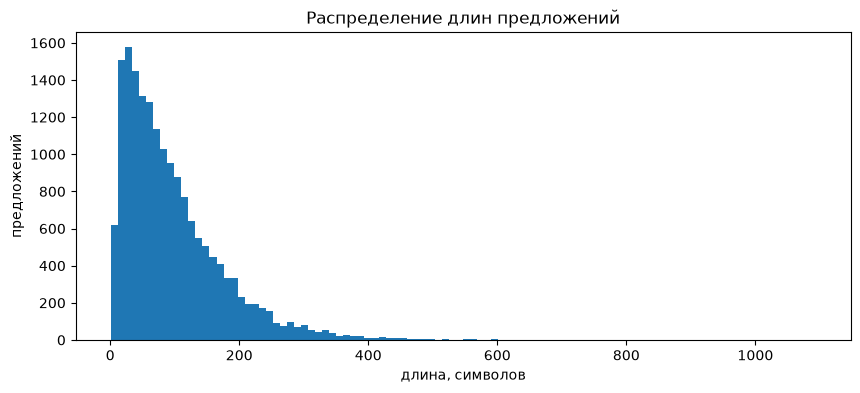

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(lengths, bins=100)
ax.set_title('Распределение длин предложений')
ax.set_xlabel('длина, символов')
ax.set_ylabel('предложений')
plt.show()

Самые частые словоформы. В маленьком корпусе из одной книги среди них будут имена героев.

In [8]:
print(', '.join(f'{word} ({count})' for word, count in word_counts.most_common(40)))

и (12913), не (6535), что (6139), в (5721), он (5549), на (3592), она (3433), с (3358), я (3217), как (2685), но (2580), его (2579), это (2231), то (2040), к (1984), ее (1804), все (1792), было (1656), так (1424), сказал (1412), а (1397), же (1324), ему (1253), о (1243), за (1204), левин (1134), только (1016), ты (992), по (942), у (914), был (900), когда (863), из (836), для (827), сказала (827), бы (822), да (819), от (813), теперь (812), вы (758)


Самые короткие строки — на них хорошо видны артефакты форматирования.

In [9]:
short_lines = sorted({text for text in ru_texts if len(text) <= 4})
print(f'Разных строк длиной до 4 символов: {len(short_lines)}')
print(short_lines)

Разных строк длиной до 4 символов: 42
['I', 'II', 'III', 'IV', 'IX', 'V', 'VI', 'VII', 'VIII', 'X', 'XI', 'XII', 'XIII', 'XIV', 'XIX', 'XV', 'XVI', 'XVII', 'XX', 'XXI', 'XXII', 'XXIV', 'XXIX', 'XXV', 'XXVI', 'XXX', 'XXXI', 'XXXV', 'А?', 'Бац!', 'Во!', 'Где?', 'Да!', 'Да.', 'Да?', 'Жив!', 'Иди.', 'Как?', 'Мха!', 'Нет.', 'Ну?', 'Я...']


**Набор символов.** Символ, которого нет в корпусе, токенизатор не сможет выучить и заменит на `[UNK]`.
Проверяем, какие символы кроме русских букв встречаются, и есть ли в корпусе символы, обычные для современных текстов.

In [10]:
char_counts = Counter(char for text in ru_texts for char in text)
other_chars = {
    char: count
    for char, count in char_counts.items()
    if not re.fullmatch(r'[а-яёА-ЯЁ ]', char)
}

print(f'Разных символов в корпусе: {len(char_counts)}')
print()
print('Кроме русских букв и пробела:')
print(', '.join(f'{char!r} ({count})' for char, count in Counter(other_chars).most_common()))

Разных символов в корпусе: 134

Кроме русских букв и пробела:
',' (39345), '-' (23550), '.' (19395), '?' (2331), '"' (1551), '!' (1544), ';' (1108), 'e' (715), ':' (706), 'a' (462), 'n' (362), 'I' (354), 's' (333), 'i' (304), 'X' (302), 'l' (267), 'r' (264), 't' (259), 'o' (241), 'm' (227), 'u' (218), ')' (158), 'd' (157), 'c' (153), '(' (151), 'V' (120), 'p' (114), "'" (79), 'h' (74), 'f' (60), 'b' (55), 'g' (47), 'v' (41), 'L' (40), 'M' (32), 'z' (28), 'j' (19), 'x' (18), 'y' (17), 'C' (17), 'q' (17), 'A' (16), 'P' (13), 'w' (10), 'D' (9), 'E' (9), '1' (8), 'k' (8), 'J' (7), 'B' (6), '8' (6), 'T' (5), 'N' (5), 'K' (5), '6' (5), 'Q' (5), 'O' (5), 'H' (4), 'U' (4), '2' (4), '3' (4), 'S' (3), '0' (3), 'R' (2), '7' (2), '5' (2), '9' (2), 'Z' (2), 'W' (2), '4' (1), 'F' (1), 'Y' (1)


In [11]:
modern_chars = ['ё', 'Ё', '—', '–', '«', '»', '…', '№', '%', '€']

pd.DataFrame({
    'символ': modern_chars,
    'раз в корпусе': [char_counts.get(char, 0) for char in modern_chars],
}).set_index('символ').T

символ,ё,Ё,—,–,«,»,…,№,%,€
раз в корпусе,0,0,0,0,0,0,0,0,0,0


**Что показал осмотр:**

- **Корпус маленький.** 17 496 предложений, 1.69 млн символов, ~270 тыс. слов. Из 32 809 разных словоформ 18 402 (56%) встречаются
  всего один раз: токенизатор не сможет выучить их целиком и будет собирать из кусочков. Для сравнения, токенизаторы RuBERT обучались
  на гигабайтах текстов.
- **По сути это одна книга, «Анна Каренина».** Среди 30 самых частых словоформ есть `левин`. Лексика — проза XIX века,
  современных слов вроде «загуглить» здесь нет и быть не может.
- **Артефакты форматирования:**
  - прямая речь оформлена двойным дефисом `--` вместо тире (поэтому `-` — второй по частоте символ после запятой);
  - заголовки глав римскими цифрами (`I`, `XIV`, `XXXV`) идут отдельными строками;
  - встречаются многоточия из 4–5 точек.
- **Латиница** — это французские и английские вставки в тексте Толстого. Это настоящий текст, а не мусор, поэтому её оставляем.
- **Пустых строк нет**, а 318 повторов — короткие реплики вроде «Да.» или «Ну?». Это нормальный текст, не ошибка.
- **Нет символов современного текста:** `ё` (в книге везде «е»: `ее` встречается 1 804 раза), тире `—`, кавычки `«»`, `…`, `№`, `%`, `€`,
  а цифр всего несколько десятков. Если ничего не сделать, токенизатор вернёт на них `[UNK]`. Это учтём при очистке и настройке токенизатора.